# Olist E-commerce Analysis

This notebook analyses about 99,000 orders from a Brazilian online marketplace
(Olist, September 2016 to October 2018). The data is stored in PostgreSQL, queried
with SQL and analysed in Python.

**Questions answered**
1. How do orders and revenue change over time?
2. Which product categories earn the most?
3. Does late delivery affect customer reviews?
4. Which states have the slowest delivery?
5. Which customer groups are the most valuable? (RFM segmentation)

**Note:** revenue is the sum of item prices (freight excluded) on delivered orders, in BRL.

## 1. Setup and data checks

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

In [2]:
password = getpass("PostgreSQL password: ")

engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="olist",
))

pd.read_sql("SELECT COUNT(*) AS orders FROM orders", engine)

,orders
0,99441


In [3]:
df_orders = pd.read_sql("SELECT * FROM orders", engine)
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


In [4]:
df_orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [5]:
# Which order statuses have no delivery date?
df_orders[df_orders["order_delivered_customer_date"].isna()]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

**Observations**

- The `orders` table contains 99,441 rows, and each row is a unique order.
- Missing values appear only in the order timestamp columns. The delivery date
  (`order_delivered_customer_date`) is missing for 2,965 orders (about 3%).
  `order_approved_at` is missing for 160 orders and `order_delivered_carrier_date`
  for 1783 orders.
- The missing delivery dates belong mainly to orders that were not delivered,
  such as shipped, canceled, unavailable, invoiced and processing orders. This is
  expected, because these orders have no delivery date yet or never will.
- 8 orders are marked as delivered but have no delivery date. These are data
  quality exceptions.
- Decision: delivery-time analysis uses only delivered orders that have a delivery
  date, so the missing values do not affect the results.

## 2. Monthly revenue trend
Monthly revenue for delivered orders. The first months of 2016 and the last months
of 2018 are incomplete, so the chart covers only complete months.

In [6]:
query_monthly_revenue = """
SELECT TO_CHAR(o.order_purchase_timestamp, 'YYYY-MM') AS month,
       ROUND(SUM(i.price), 2) AS revenue
FROM orders o
JOIN order_items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY month
ORDER BY month;
"""

df_monthly = pd.read_sql(query_monthly_revenue, engine)
df_monthly["revenue"] = df_monthly["revenue"].astype(float)
df_monthly.tail()

,month,revenue
18,2018-04,973534.09
19,2018-05,977544.69
20,2018-06,856077.86
21,2018-07,867953.46
22,2018-08,838576.64


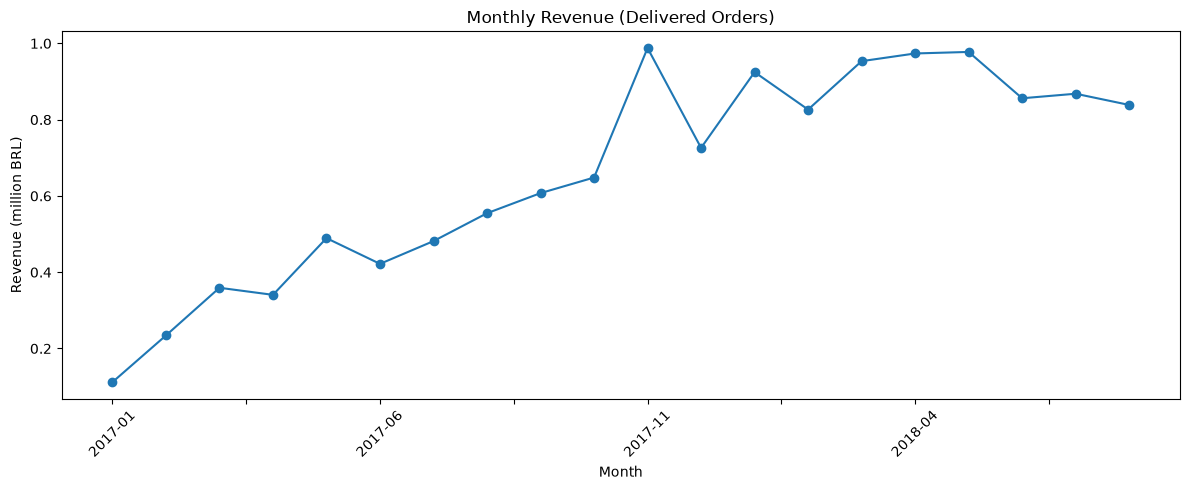

In [7]:
# keep complete months only
chart_df = df_monthly[(df_monthly["month"] >= "2017-01") & (df_monthly["month"] <= "2018-08")].copy()
chart_df["revenue_m"] = chart_df["revenue"] / 1_000_000

chart_df.plot(x="month", y="revenue_m", kind="line", marker="o", figsize=(12, 5), legend=False)
plt.title("Monthly Revenue (Delivered Orders)")
plt.xlabel("Month")
plt.ylabel("Revenue (million BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/monthly_revenue.png", bbox_inches="tight")
plt.show()

In [8]:
chart_df.nlargest(3, "revenue")[["month", "revenue"]]

,month,revenue
13,2017-11,987765.37
19,2018-05,977544.69
18,2018-04,973534.09


**Finding:** revenue grew from about 0.1 million BRL in January 2017 to a peak of
about 1.0 million BRL in November 2017, which is consistent with Black Friday. In 2018
it stayed roughly flat, between about 0.8 and 1.0 million BRL.

## 3. Top product categories
Top 10 product categories by revenue on delivered orders. Products without a category
name are excluded. Each share is calculated against the revenue of all categories.

In [9]:
query_top_categories = """
SELECT c.product_category_name_english AS category,
       ROUND(SUM(i.price), 2) AS revenue,
       ROUND(SUM(i.price) * 100.0 / SUM(SUM(i.price)) OVER (), 2) AS revenue_share_pct
FROM orders o
JOIN order_items i ON o.order_id = i.order_id
JOIN products p ON i.product_id = p.product_id
JOIN category_translation c ON p.product_category_name = c.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY c.product_category_name_english
ORDER BY revenue DESC
LIMIT 10;
"""

df_categories = pd.read_sql(query_top_categories, engine)
df_categories[["revenue", "revenue_share_pct"]] = df_categories[["revenue", "revenue_share_pct"]].astype(float)
df_categories

,category,revenue,revenue_share_pct
0,health_beauty,1233131.72,9.45
1,watches_gifts,1166176.98,8.94
2,bed_bath_table,1023434.76,7.85
3,sports_leisure,954852.55,7.32
4,computers_accessories,888724.61,6.81
5,furniture_decor,711927.69,5.46
6,housewares,615628.69,4.72
7,cool_stuff,610204.10,4.68
8,auto,578966.65,4.44
9,toys,471286.48,3.61


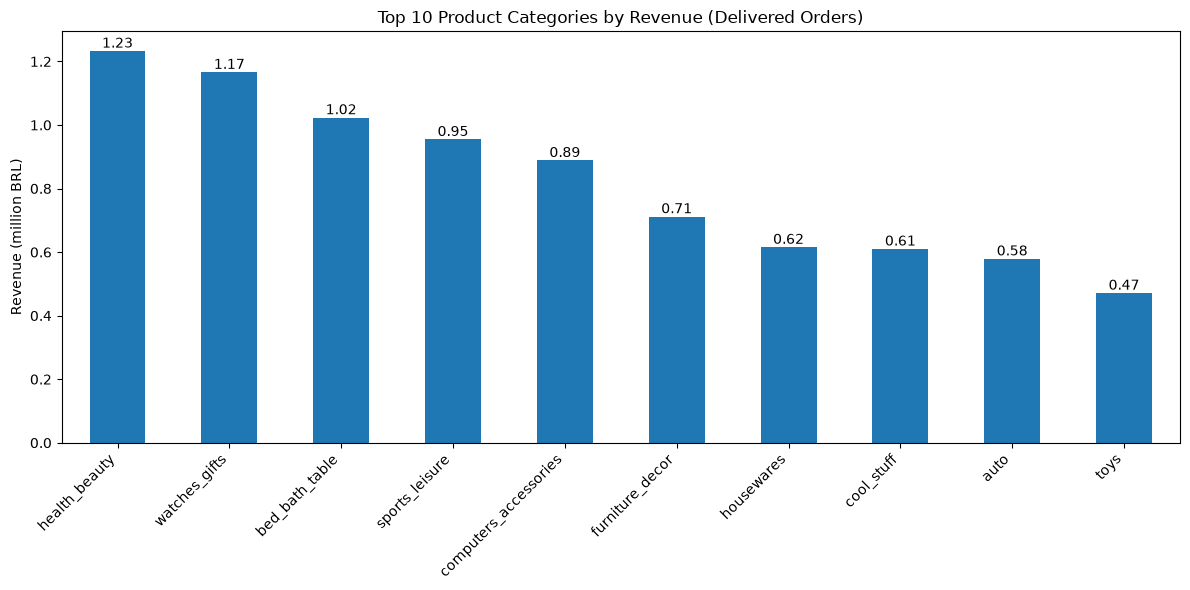

In [10]:
df_categories["revenue_m"] = df_categories["revenue"] / 1_000_000

ax = df_categories.plot(x="category", y="revenue_m", kind="bar", figsize=(12, 6), legend=False)
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Top 10 Product Categories by Revenue (Delivered Orders)")
plt.xlabel("")
plt.ylabel("Revenue (million BRL)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("charts/top_categories.png", bbox_inches="tight")
plt.show()

In [11]:
top5_share = df_categories["revenue_share_pct"].head(5).sum()
print(f"Top 5 categories: {top5_share:.1f}% of revenue")

Top 5 categories: 40.4% of revenue


**Finding:** health & beauty, watches & gifts, and bed, bath & table are the top three
categories by revenue. The top five categories together make up 40.4% of revenue and
the top ten make up 63.3%. No single category exceeds 10% of revenue (health & beauty
is the highest at 9.45%), so revenue is spread across a group of leading categories and
does not depend on one product line.

## 4. Delivery performance and customer satisfaction
Delivered orders with a recorded delivery date. An order is late if it arrived after
the estimated delivery date.

In [12]:
query_late_share = """
SELECT COUNT(*) AS delivered_orders,
       ROUND(100.0 * COUNT(*) FILTER (WHERE order_delivered_customer_date > order_estimated_delivery_date)
             / COUNT(*), 2) AS late_pct
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL;
"""
pd.read_sql(query_late_share, engine)

,delivered_orders,late_pct
0,96470,8.11


In [13]:
query_review = """
SELECT CASE
         WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 'Late'
         ELSE 'On time'
       END AS delivery_status,
       ROUND(AVG(r.review_score), 2) AS avg_score
FROM orders o
JOIN reviews r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY delivery_status;
"""
df_review = pd.read_sql(query_review, engine)
df_review["avg_score"] = df_review["avg_score"].astype(float)
df_review

,delivery_status,avg_score
0,On time,4.29
1,Late,2.57


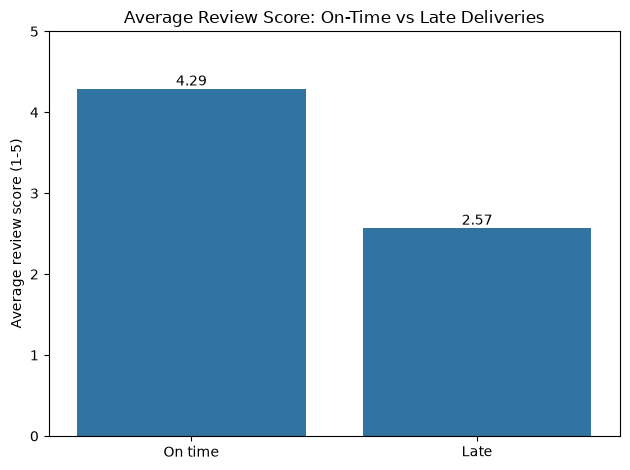

In [14]:
ax = sns.barplot(data=df_review, x="delivery_status", y="avg_score", order=["On time", "Late"])
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.ylim(0, 5)
plt.title("Average Review Score: On-Time vs Late Deliveries")
plt.xlabel("")
plt.ylabel("Average review score (1-5)")
plt.tight_layout()
plt.savefig("charts/review_late_vs_ontime.png", bbox_inches="tight")
plt.show()

**Finding 1:** 8.1% of delivered orders arrived after the estimated date. Orders
delivered on time average a review score of 4.29, while late orders average 2.57, which
is 1.72 points lower. This shows an association between late delivery and low scores,
not proof that lateness causes them. Review scores are averaged over reviews, and a few
orders have more than one review.

In [15]:
query_states = """
SELECT c.customer_state,
       ROUND(AVG(o.order_delivered_customer_date::date - o.order_purchase_timestamp::date), 1) AS avg_delivery_days,
       COUNT(*) AS orders
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state
ORDER BY avg_delivery_days DESC
LIMIT 10;
"""
df_states = pd.read_sql(query_states, engine)
df_states["avg_delivery_days"] = df_states["avg_delivery_days"].astype(float)

query_overall = """
SELECT ROUND(AVG(order_delivered_customer_date::date - order_purchase_timestamp::date), 1)
FROM orders
WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL;
"""
overall_avg = float(pd.read_sql(query_overall, engine).iloc[0, 0])

df_states

,customer_state,avg_delivery_days,orders
0,RR,29.3,41
1,AP,27.2,67
2,AM,26.4,145
3,AL,24.5,397
4,PA,23.7,946
5,MA,21.5,717
6,SE,21.5,335
7,CE,21.2,1279
8,AC,21.0,80
9,PB,20.4,517


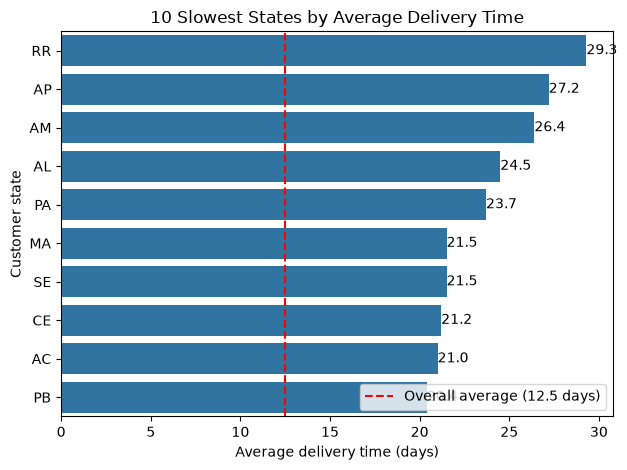

In [16]:
ax = sns.barplot(data=df_states, x="avg_delivery_days", y="customer_state", color="tab:blue")
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.axvline(overall_avg, color="red", linestyle="--", label=f"Overall average ({overall_avg:.1f} days)")
plt.legend(loc="lower right")
plt.title("10 Slowest States by Average Delivery Time")
plt.xlabel("Average delivery time (days)")
plt.ylabel("Customer state")
plt.tight_layout()
plt.savefig("charts/slowest_states.png", bbox_inches="tight")
plt.show()

**Finding 2:** the overall average delivery time is 12.5 days. The ten slowest states
are all in the north and northeast of Brazil, with averages between 20.4 and 29.3 days,
which is 1.6 to 2.3 times the overall average. The slowest is RR at 29.3 days. RR, AP
and AC have fewer than 100 delivered orders each, so their averages are less stable, but
larger states such as PA (946 orders), MA (717) and CE (1,279) show the same pattern.

## 5. Customer segmentation (RFM)
Each customer is scored from 1 to 5 on:
- **Recency:** days since the last order (a recent buyer scores 5)
- **Monetary:** total spend (the highest spenders score 5)
- **Frequency:** number of orders. About 97% of customers ordered once, so it separates
  customers very little in this dataset.

Rules are applied in this order, and the first match wins:
1. Champions: recency score 4 or 5 and monetary score 4 or 5
2. Repeat buyers: two or more orders
3. At risk: recency score 1 or 2 and monetary score 4 or 5
4. Recent low-value: recency score 4 or 5
5. Other: everyone else

The score directions were validated by checking the average recency and spend per score.

In [17]:
query_rfm = """
SELECT c.customer_unique_id,
       MAX(o.order_purchase_timestamp) AS last_purchase,
       COUNT(DISTINCT o.order_id) AS frequency,
       ROUND(SUM(i.price), 2) AS monetary
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_unique_id;
"""
df_rfm = pd.read_sql(query_rfm, engine)
df_rfm["monetary"] = df_rfm["monetary"].astype(float)
df_rfm["last_purchase"] = pd.to_datetime(df_rfm["last_purchase"])
df_rfm.describe()

,last_purchase,frequency,monetary
count,93358,93358.000000,93358.000000
mean,2018-01-04 03:47:36.045363,1.033420,141.621480
min,2016-09-15 12:16:38,1.000000,0.850000
25%,2017-09-17 18:25:15,1.000000,47.650000
50%,2018-01-23 00:12:12.500000,1.000000,89.730000
75%,2018-05-07 17:22:34.750000,1.000000,154.737500
max,2018-08-29 15:00:37,15.000000,13440.000000
std,NaN,0.209097,215.694014


In [18]:
snapshot = df_rfm["last_purchase"].max() + pd.Timedelta(days=1)
df_rfm["recency"] = (snapshot - df_rfm["last_purchase"]).dt.days

df_rfm["r_score"] = pd.qcut(df_rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
df_rfm["m_score"] = pd.qcut(df_rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

In [19]:
conditions = [
    (df_rfm["r_score"] >= 4) & (df_rfm["m_score"] >= 4),
    df_rfm["frequency"] >= 2,
    (df_rfm["r_score"] <= 2) & (df_rfm["m_score"] >= 4),
    df_rfm["r_score"] >= 4,
]
names = ["Champions", "Repeat buyers", "At risk", "Recent low-value"]
df_rfm["segment"] = np.select(conditions, names, default="Other")

df_rfm["segment"].value_counts()

segment
Other               40687
Recent low-value    21772
Champions           15389
At risk             13646
Repeat buyers        1864
Name: count, dtype: int64

In [20]:
seg = df_rfm.groupby("segment")["monetary"].agg(customers="count", revenue="sum")
seg["pct_customers"] = (seg["customers"] / seg["customers"].sum() * 100).round(1)
seg["pct_revenue"] = (seg["revenue"] / seg["revenue"].sum() * 100).round(1)
seg["avg_spend"] = (seg["revenue"] / seg["customers"]).round(2)
seg.sort_values("revenue", ascending=False)

,customers,revenue,pct_customers,pct_revenue,avg_spend
segment,,,,,
Champions,15389,4176797.03,16.5,31.6,271.41
At risk,13646,3795588.68,14.6,28.7,278.15
Other,40687,3614535.38,43.6,27.3,88.84
Recent low-value,21772,1212650.08,23.3,9.2,55.70
Repeat buyers,1864,421926.94,2.0,3.2,226.36


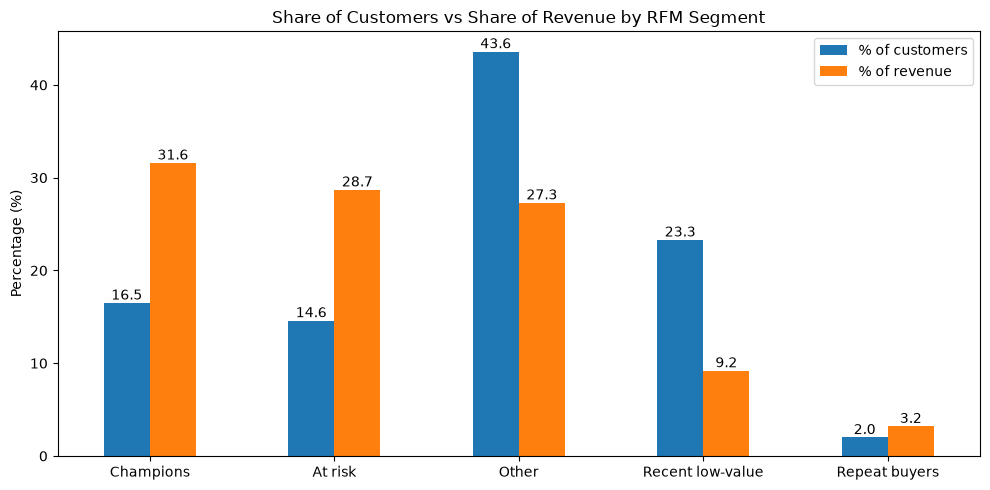

In [21]:
plot_df = seg[["pct_customers", "pct_revenue"]].sort_values("pct_revenue", ascending=False)
ax = plot_df.plot(kind="bar", figsize=(10, 5))
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f")
plt.title("Share of Customers vs Share of Revenue by RFM Segment")
plt.xlabel("")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["% of customers", "% of revenue"])
plt.tight_layout()
plt.savefig("charts/rfm_segments.png", bbox_inches="tight")
plt.show()

**Finding:** Champions and At-risk customers are 31% of customers but 60% of revenue.
The At-risk group holds about 3.8 million BRL in lifetime spend, which makes it the
best target for a win-back campaign. Recent low-value customers are 23% of customers
but only 9% of revenue. The segment rules are my own definitions.

## Conclusions

**Key findings**
1. Revenue grew strongly through 2017, reaching a peak of about 1.0 million BRL in
   November 2017 (consistent with Black Friday), and stayed roughly flat in 2018.
2. Revenue is concentrated in a group of leading categories. The top five make up
   40.4% of revenue and the top ten make up 63.3%, but no single category exceeds 10%.
3. Late delivery is linked to lower customer satisfaction. 8.1% of delivered orders
   arrived late, and these orders average a review score of 2.57 against 4.29 for
   on-time orders.
4. Delivery is slowest in the north and northeast of Brazil. The ten slowest states
   average between 20.4 and 29.3 days, against 12.5 days overall.
5. About 97% of customers ordered only once. Champions and At-risk customers are 31%
   of customers but 60% of revenue.

**Recommendations**
- Improve delivery estimates and logistics in the north and northeast.
- Run a win-back campaign for At-risk customers, who hold about 3.8 million BRL in
  lifetime spend.
- Encourage a second purchase from Recent low-value customers, who bought recently.
- Protect Champions with loyalty benefits.

**Limitations and next steps**
- Review results show an association, not a proven cause.
- Segment rules are my own definitions, and frequency separates customers very little.
- Next step: compare seller and customer states to test whether distance explains the
  slow delivery in the north and northeast.